In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torch.utils.data import DataLoader, Dataset
import numpy as np
import os
import rasterio
from tqdm import tqdm
import torchvision.transforms.functional as TF

In [2]:
base_dir2 = 'D:/dataset/AMAZON/'

# Training folder
train_img_dir = os.path.join(base_dir2, 'Training/image')
train_mask_dir = os.path.join(base_dir2, 'Training/label')

# Validation folder
val_img_dir = os.path.join(base_dir2, 'Validation/images')
val_mask_dir = os.path.join(base_dir2, 'Validation/masks')

# Test folder
test_img_dir = os.path.join(base_dir2, 'Test/image')
test_mask_dir = os.path.join(base_dir2, 'Test/mask')

In [3]:
# -------------------------------
# Dataset Loader using rasterio
# -------------------------------
class Sentinel2Dataset(Dataset):
    def __init__(self, image_dir, mask_dir):
        self.image_paths = sorted([
            os.path.join(image_dir, fname)
            for fname in os.listdir(image_dir)
            if fname.endswith('.tif')
        ])
        self.mask_paths = sorted([
            os.path.join(mask_dir, fname)
            for fname in os.listdir(mask_dir)
            if fname.endswith('.tif')
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        with rasterio.open(self.image_paths[idx]) as src:
            image = src.read([1, 2, 3, 4]).astype(np.float32)  # 4-band RGB+NIR

        with rasterio.open(self.mask_paths[idx]) as src:
            mask = src.read(1).astype(np.float32)

        image = image / 255.0
        mask = mask / 255.0

        image = torch.from_numpy(image)
        mask = torch.from_numpy(mask).unsqueeze(0)

        # Resize both to 64x64 to match expected input size
        image = TF.resize(image, [64, 64])
        mask = TF.resize(mask, [64, 64])

        return image, mask

In [4]:
# -------------------------------
# TransUNet-like Architecture
# -------------------------------
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class UpBlock(nn.Module):
    def __init__(self, in_channels, bridge_channels, out_channels):
        super(UpBlock, self).__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, 2, stride=2)
        self.conv = ConvBlock(out_channels + bridge_channels, out_channels)

    def forward(self, x, bridge):
        up = self.up(x)
        out = torch.cat([up, bridge], dim=1)
        return self.conv(out)

class SimpleTransUNet(nn.Module):
    def __init__(self, in_channels=4, num_classes=1):
        super(SimpleTransUNet, self).__init__()
        resnet = models.resnet50(pretrained=True)
        resnet.conv1 = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.enc2 = nn.Sequential(resnet.maxpool, resnet.layer1)
        self.enc3 = resnet.layer2
        self.enc4 = resnet.layer3
        self.enc5 = resnet.layer4

        self.proj = nn.Conv2d(2048, 512, kernel_size=1)

        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model=512, nhead=8),
            num_layers=2
        )

        self.up4 = UpBlock(2048, 1024, 512)
        self.up3 = UpBlock(512, 512, 256)
        self.up2 = UpBlock(256, 256, 128)
        self.up1 = UpBlock(128, 64, 64)
        self.final = nn.Conv2d(64, num_classes, 1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(enc1)
        enc3 = self.enc3(enc2)
        enc4 = self.enc4(enc3)
        enc5 = self.enc5(enc4)

        x_proj = self.proj(enc5)
        b, c, h, w = x_proj.size()
        tokens = x_proj.view(b, c, -1).permute(2, 0, 1)
        transformed = self.transformer(tokens).permute(1, 2, 0).view(b, c, h, w)

        x = self.up4(enc5, enc4)
        x = self.up3(x, enc3)
        x = self.up2(x, enc2)
        x = self.up1(x, enc1)
        return torch.sigmoid(self.final(x))


In [25]:
# -------------------------------
# Validation Function
# -------------------------------
def evaluate_model(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    val_acc = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            masks = (masks > 0.5).float()
            preds = model(images)
            preds = nn.functional.interpolate(preds, size=masks.shape[2:], mode='bilinear', align_corners=False)
            loss = criterion(preds, masks)
            acc = ((preds > 0.5).float() == masks).float().mean().item()
            val_loss += loss.item()
            val_acc += acc
    return val_loss / len(val_loader), val_acc / len(val_loader)

# -------------------------------
# Training Function
# -------------------------------
def train_model(model, train_loader, val_loader=None, num_epochs=10, lr=1e-4):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        'accuracy': [],
        'val_accuracy': [],
        'loss': [],
        'val_loss': []
    }

    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0.0
        epoch_acc = 0.0

        for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
            images, masks = images.to(device), masks.to(device)
            masks = (masks > 0.5).float()
            preds = model(images)
            preds = nn.functional.interpolate(preds, size=masks.shape[2:], mode='bilinear', align_corners=False)
            loss = criterion(preds, masks)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            acc = ((preds > 0.5).float() == masks).float().mean().item()
            epoch_loss += loss.item()
            epoch_acc += acc
        print(f"Batch Loss: {loss.item():.4f}, Batch Accuracy: {acc:.4f}")

        avg_train_loss = epoch_loss / len(train_loader)
        avg_train_acc = epoch_acc / len(train_loader)

        # Evaluate on validation set
        if val_loader:
            avg_val_loss, avg_val_acc = evaluate_model(model, val_loader, criterion, device)
            print(f"Epoch [{epoch+1}/{num_epochs}] → Train Loss: {avg_train_loss:.4f}, Train Acc: {avg_train_acc:.4f}, Val Loss: {avg_val_loss:.4f}, Val Acc: {avg_val_acc:.4f}")
            history['val_loss'].append(avg_val_loss)
            history['val_accuracy'].append(avg_val_acc)
        else:
            avg_val_loss = 0.0
            avg_val_acc = 0.0
            print(f"Epoch [{epoch+1}/{num_epochs}] → Train Loss: {avg_train_loss:.4f}, Train Acc: {avg_train_acc:.4f}")

        history['loss'].append(avg_train_loss)
        history['accuracy'].append(avg_train_acc)

    # Final evaluation and save history
    if val_loader:
        final_val_loss, _ = evaluate_model(model, val_loader, criterion, device)
        print(f"Final Validation Loss: {final_val_loss:.4f}")

    np.save('transunet-4d-history.npy', history)
    return history

In [26]:
# -------------------------------
# Run Training
# -------------------------------
train_dataset = Sentinel2Dataset(train_img_dir, train_mask_dir)
val_dataset = Sentinel2Dataset(val_img_dir, val_mask_dir)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4)

model = SimpleTransUNet(in_channels=4)
history = train_model(model, train_loader, val_loader, num_epochs=10)

Epoch 1: 100%|██████████| 125/125 [03:05<00:00,  1.48s/it]


Batch Loss: 0.3128, Batch Accuracy: 0.9893
Epoch [1/10] → Train Loss: 0.4123, Train Acc: 0.9651, Val Loss: 0.3134, Val Acc: 0.9893


Epoch 2: 100%|██████████| 125/125 [03:01<00:00,  1.45s/it]


Batch Loss: 0.2406, Batch Accuracy: 0.9951
Epoch [2/10] → Train Loss: 0.2708, Train Acc: 0.9941, Val Loss: 0.2385, Val Acc: 0.9951


Epoch 3: 100%|██████████| 125/125 [02:43<00:00,  1.31s/it]


...

Batch Loss: 0.0775, Batch Accuracy: 0.9961
Epoch [8/10] → Train Loss: 0.0842, Train Acc: 0.9961, Val Loss: 0.0774, Val Acc: 0.9961


Epoch 9: 100%|██████████| 125/125 [02:49<00:00,  1.36s/it]


Batch Loss: 0.0665, Batch Accuracy: 0.9961
Epoch [9/10] → Train Loss: 0.0718, Train Acc: 0.9961, Val Loss: 0.0662, Val Acc: 0.9961


Epoch 10: 100%|██████████| 125/125 [02:42<00:00,  1.30s/it]


Batch Loss: 0.0574, Batch Accuracy: 0.9961
Epoch [10/10] → Train Loss: 0.0618, Train Acc: 0.9961, Val Loss: 0.0577, Val Acc: 0.9961
Final Validation Loss: 0.0577


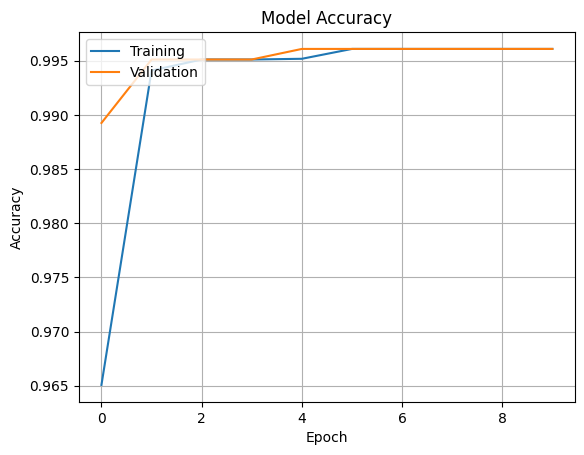

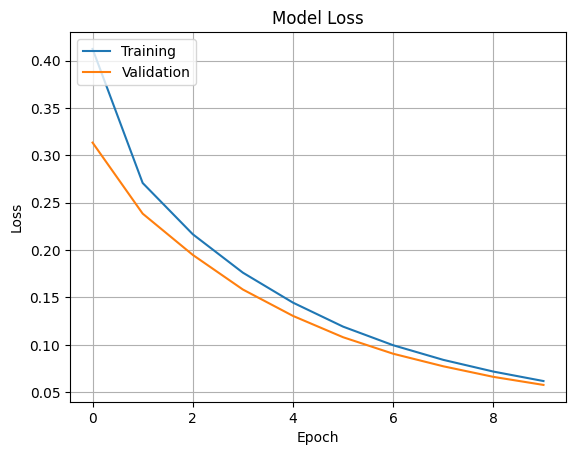

In [33]:
# Plot Accuracy and Loss
history = np.load('transunet-4d-history.npy', allow_pickle=True).item()
import matplotlib.pyplot as plt
# Accuracy plot
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Training', 'Validation'], loc='upper left')
plt.grid(True)
plt.show()

# Loss plot
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Training', 'Validation'], loc='upper left')
plt.grid(True)
plt.show()

In [32]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
